# Cellular functional-state analysis

Figure 8: age-dependent importance, technical covariates, and Hallmark associations.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scdecage.tutorials_utils.plotting import DATA_ROOT, setup, show_figure
ANALYSIS_DIR = Path('outputs/model_analyses/functional_analysis')
OUTPUT_DIR = Path('outputs/cellular_states')
setup(display_fraction=.63, display_width=672)

## Model inference and functional experiments

Saved outputs show the manuscript analysis across test partitions. Supply the model inputs, full-count H5AD, cell annotations (`cell_index`, `barcode`, `sex`), and gene-set files to rerun the analysis.

In [ ]:
MODEL_INPUTS = [{'checkpoint': '', 'data_root': '', 'cell_order': ''}]
RAW_COUNTS = ''
CELL_ANNOTATIONS = ''
HALLMARK_GMT = ''
CELL_CYCLE_GENES = ''
CELL_LABELS = {'naive thymus-derived CD4-positive, alpha-beta T cell': 'Naive CD4 T', 'central memory CD4-positive, alpha-beta T cell': 'Central-memory CD4 T', 'effector memory CD4-positive, alpha-beta T cell': 'Effector-memory CD4 T', 'regulatory T cell': 'Regulatory T', 'CD4-positive, alpha-beta cytotoxic T cell': 'Cytotoxic CD4 T', 'CD4-positive, alpha-beta T cell': 'CD4+ T', 'naive thymus-derived CD8-positive, alpha-beta T cell': 'Naive CD8 T', 'central memory CD8-positive, alpha-beta T cell': 'Central-memory CD8 T', 'effector memory CD8-positive, alpha-beta T cell': 'Effector-memory CD8 T', 'CD8-positive, alpha-beta T cell': 'CD8+ T', 'natural killer cell': 'NK', 'CD16-negative, CD56-bright natural killer cell, human': 'CD56-bright NK', 'CD14-positive monocyte': 'CD14+ monocyte', 'CD14-low, CD16-positive monocyte': 'CD16+ monocyte', 'naive B cell': 'Naive B', 'memory B cell': 'Memory B', 'transitional stage B cell': 'Transitional B', 'hematopoietic precursor cell': 'Hematopoietic precursor', 'mucosal-associated invariant T cell': 'MAIT', 'conventional dendritic cell': 'Conventional DC', 'plasmacytoid dendritic cell': 'Plasmacytoid DC', 'gamma-delta T cell': 'Gamma-delta T', 'double negative thymocyte': 'Double-negative T', 'innate lymphoid cell': 'Innate lymphoid', 'dendritic cell': 'Dendritic cell', 'plasmablast': 'Plasmablast', 'platelet': 'Platelet', 'erythrocyte': 'Erythrocyte'}


In [ ]:
import torch
import anndata as ad
from scipy import sparse
from scdecage.tutorials_utils.inference import load_experiment_model, infer_donor, precision_context
from scdecage.tutorials_utils.functional_scores import score, technical_analysis, pathway_analysis

@torch.inference_mode()
def functional_cell_weights(model_inputs):
    frames = []
    for specification in model_inputs:
        model, data = load_experiment_model(specification)
        for item in data:
            _, _, _, representations, _ = infer_donor(model, item, dtype=torch.float16)
            with precision_context(representations.device, torch.float16):
                logits = model.aggregator.cell_weight_head(model.aggregator.cell_proj(representations)).squeeze(-1)
            frame = data.metadata.iloc[item['cell_indices']][['cell_index', 'donor_id', 'age_years', 'cell_type']].copy()
            frame['raga_logit'] = logits.float().cpu().numpy()
            frames.append(frame)
    cells = pd.concat(frames, ignore_index=True)
    if not cells.cell_index.is_unique:
        raise ValueError('Test cells must be disjoint across the supplied models.')
    return cells

def age_importance_table(cells):
    age = cells.copy()
    age['cell_type'] = age.cell_type.map(CELL_LABELS).fillna(age.cell_type)
    age['e'] = np.exp(age.raga_logit - age.groupby('donor_id').raga_logit.transform('max'))
    age['weight'] = age.e / age.groupby('donor_id').e.transform('sum')
    age['fraction'] = 1 / age.groupby('donor_id').cell_index.transform('count')
    age = age.groupby(['donor_id', 'cell_type'], observed=True).agg(
        age=('age_years', 'first'), weight=('weight', 'sum'), fraction=('fraction', 'sum')).reset_index()
    age['excess_attention_pp'] = 100 * (age.weight - age.fraction)
    cuts = age[['donor_id', 'age']].drop_duplicates().age.quantile([.25, .5, .75]).to_numpy()
    age['quartile'] = ['Q' + str(q + 1) for q in np.searchsorted(cuts, age.age, side='right')]
    return age

def expression_for_functional_scoring(cells, raw_counts, cell_annotations):
    annotations = pd.read_parquet(cell_annotations)[['cell_index', 'barcode', 'sex']]
    metadata = cells[['cell_index', 'donor_id', 'age_years', 'cell_type']].merge(
        annotations, on='cell_index', validate='one_to_one')
    metadata['cell_type_short'] = metadata.cell_type.map(CELL_LABELS)
    types = ['Naive CD4 T', 'Naive CD8 T', 'Effector-memory CD8 T', 'NK', 'CD14+ monocyte', 'CD16+ monocyte']
    metadata = metadata.loc[metadata.cell_type_short.isin(types)].copy()
    raw = ad.read_h5ad(raw_counts, backed='r')
    try:
        metadata['raw_row'] = raw.obs_names.get_indexer(metadata.barcode)
        if (metadata.raw_row < 0).any():
            raise ValueError('Every selected cell barcode must occur in the raw count matrix.')
        metadata = metadata.sort_values('raw_row').reset_index(drop=True)
        raw_obs = raw.obs.iloc[metadata.raw_row.to_numpy()]
        for source, target in [('nCount_RNA', 'total_counts'), ('nFeature_RNA', 'detected_genes'), ('percent.mt', 'mitochondrial_percent')]:
            metadata[target] = raw_obs[source].to_numpy(float)
        symbols = raw.var.feature_name.astype(str).to_numpy()
        columns = np.flatnonzero(~pd.Index(symbols).duplicated(keep='first') & (symbols != ''))
        blocks = [sparse.csr_matrix(raw.X[metadata.raw_row.to_numpy()[i:i+5000]])[:, columns]
                  for i in range(0, len(metadata), 5000)]
        expression = sparse.vstack(blocks, format='csr')
    finally:
        raw.file.close()
    return ad.AnnData(expression, obs=metadata.set_index('barcode', drop=False),
                      var=pd.DataFrame(index=symbols[columns]))


In [ ]:
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
cells = functional_cell_weights(MODEL_INPUTS)
age_importance = age_importance_table(cells)
age_importance.to_csv(ANALYSIS_DIR / 'age_by_donor.csv', index=False)
expression = expression_for_functional_scoring(cells, RAW_COUNTS, CELL_ANNOTATIONS)
cell_scores, gene_coverage = score(expression, Path(HALLMARK_GMT), Path(CELL_CYCLE_GENES), ANALYSIS_DIR)
cell_scores = cell_scores.merge(cells[['cell_index', 'raga_logit']], on='cell_index', validate='one_to_one')
technical_analysis(cell_scores, 15, 2000, '', ANALYSIS_DIR)
hallmark_donors = pathway_analysis(cell_scores, gene_coverage, 15, .2, 2000, '', 'test', ANALYSIS_DIR, ANALYSIS_DIR / 'age_by_donor.csv')


## Load analysis


In [2]:
age_importance = pd.read_csv(ANALYSIS_DIR / 'age_by_donor.csv')
technical_correlations = pd.read_csv(ANALYSIS_DIR / 'source_A_technical_donor_correlations.csv')
hallmark_donors = pd.read_csv(ANALYSIS_DIR / 'source_BC_donor_hallmark_associations.csv')
hallmark_summary = pd.read_csv(ANALYSIS_DIR / 'source_B_hallmark_association_summary.csv')
source_summary = pd.DataFrame([
    ('Age-dependent cell importance', age_importance.donor_id.nunique()),
    ('Technical covariates', technical_correlations.donor_id.nunique()),
    ('Hallmark associations', hallmark_donors.donor_id.nunique()),
], columns=['Analysis', 'Individuals'])
display(source_summary)


,Analysis,Individuals
0,Age-dependent cell importance,981
1,Technical covariates,981
2,Hallmark associations,981


## Plotting calculations


In [3]:
from matplotlib.patches import FancyArrowPatch
from matplotlib.transforms import Bbox
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

TYPE_ORDER = ['Naive CD4 T', 'Naive CD8 T', 'Effector-memory CD8 T', 'NK', 'CD14+ monocyte', 'CD16+ monocyte']
AGE_ORDER = ['CD16+ monocyte', 'Central-memory CD4 T', 'NK', 'Naive B', 'Memory B', 'Effector-memory CD4 T', 'Hematopoietic precursor', 'Transitional B', 'Double-negative T', 'Regulatory T', 'Central-memory CD8 T', 'Plasmablast', 'Innate lymphoid', 'CD14+ monocyte', 'Cytotoxic CD4 T', 'Gamma-delta T', 'Platelet', 'Naive CD4 T', 'Effector-memory CD8 T', 'Naive CD8 T']
HALLMARK_ORDER = ['Interferon-alpha response', 'Interferon-gamma response', 'Inflammatory Response', 'TNF signaling via NF-kappa B', 'IL6-JAK-STAT3 signaling', 'PI3K-AKT-mTOR signaling', 'Oxidative Phosphorylation', 'Reactive Oxygen Species Pathway', 'Apoptosis', 'Unfolded Protein Response', 'DNA repair', 'Protein Secretion']
TECH_ORDER = ['Total counts', 'Detected genes', 'Mitochondrial proportion', 'S-phase score', 'G2/M-phase score']
DARK, PALE_BLUE, SKY_BLUE, PALE_PINK, CORAL_RED = '#26343C', '#D3EFF7', '#97C6E6', '#FDDFDE', '#EA7B7D'
DIV = LinearSegmentedColormap.from_list('functional_div',
    [SKY_BLUE, PALE_BLUE, '#FFFFFF', PALE_PINK, '#F6B7B2', CORAL_RED])
FUNCTIONAL_CONTRASTS = [
    ('NK', 'Interferon-alpha response', 'NK\nInterferon-alpha response'),
    ('Effector-memory CD8 T', 'Oxidative Phosphorylation', 'Memory CD8 T\nOxidative phosphorylation'),
    ('CD16+ monocyte', 'DNA repair', 'CD16+ monocyte\nDNA repair'),
]

def display_name(value):
    return str(value).replace('Effector-memory CD8 T', 'Memory CD8 T')

def render_functional_panels(input_directory, output_directory):
    inputs, directory = Path(input_directory), Path(output_directory)
    directory.mkdir(parents=True, exist_ok=True)
    age = pd.read_csv(inputs / 'age_by_donor.csv').groupby(
        ['quartile', 'cell_type'], observed=True).excess_attention_pp.mean().reset_index()
    order = [name for name in AGE_ORDER if name in set(age.cell_type)]
    technical = pd.read_csv(inputs / 'source_A_technical_summary.csv')
    r2 = pd.read_csv(inputs / 'source_A_technical_r2_summary.csv')
    summary = pd.read_csv(inputs / 'source_B_hallmark_association_summary.csv')
    hallmark = summary[summary.cell_type.isin(TYPE_ORDER) & summary.hallmark.isin(HALLMARK_ORDER)]
    donor = pd.read_csv(inputs / 'source_BC_donor_hallmark_associations.csv')
    def draw(fig, offset=(0, 0)):
        fw, fh = fig.get_size_inches()
        dx, dy = offset

        def axes(x, y, w, h):
            return fig.add_axes([(x + dx) / fw, (y + dy) / fh, w / fw, h / fh])

        def label(x, y, text):
            fig.text((x + dx) / fw, (y + dy) / fh, text, fontsize=11.5, fontweight='bold', va='top', color='#17242B')

        def ticks(ax, xsize=7.2, ysize=7.2):
            ax.tick_params(axis='x', labelsize=xsize, length=2.5, width=0.55)
            ax.tick_params(axis='y', labelsize=ysize, length=2.5, width=0.55)
            ax.set_axisbelow(True)

        def colorbar(mappable, cax, text):
            cb = fig.colorbar(mappable, cax=cax)
            cb.ax.tick_params(labelsize=5.9, length=2, width=0.4)
            cb.set_label(text, fontsize=6.5, labelpad=3)
            cb.outline.set_visible(False)
            return cb
        ax = axes(0.6755, 7.43875, 5.909, 1.4725)
        cax = axes(6.6955, 7.43875, 0.075, 1.4725)
        matrix = age.pivot(index='quartile', columns='cell_type', values='excess_attention_pp').reindex(index=['Q1', 'Q2', 'Q3', 'Q4'], columns=order)
        limit = float(np.nanquantile(abs(matrix.to_numpy()), 0.95))
        sns.heatmap(matrix, ax=ax, cmap=DIV, center=0, vmin=-limit, vmax=limit, annot=True, fmt='+.1f', annot_kws={'fontsize': 7.0}, linewidths=0.45, linecolor='white', cbar=False)
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.set_yticklabels(['Q1', 'Q2', 'Q3', 'Q4'], rotation=0)
        names = [display_name(s).replace('\n', ' ') for s in order]
        ax.set_xticklabels(names, rotation=57, ha='right', rotation_mode='anchor')
        ticks(ax, xsize=6.9, ysize=7.6)
        ax.tick_params(axis='x', length=0, pad=3)
        colorbar(ax.collections[0], cax, 'Relative importance (pp)')
        label(0.02, 9.17, 'A')
        fig.add_artist(FancyArrowPatch(((0.15 + dx) / fw, (8.57 + dy) / fh), ((0.15 + dx) / fw, (7.78 + dy) / fh), transform=fig.transFigure, arrowstyle='-|>', mutation_scale=7, lw=0.8, color='#697782'))
        fig.text((0.15 + dx) / fw, (8.77 + dy) / fh, 'Young', ha='center', fontsize=6.6)
        fig.text((0.15 + dx) / fw, (7.48 + dy) / fh, 'Old', ha='center', fontsize=6.6)
        bx = axes(1.08, 4.0, 1.48, 2.1)
        bc = axes(2.65, 4.0, 0.065, 2.1)
        bar = axes(3.03, 4.0, 0.37, 2.1)
        bm = technical.pivot(index='cell_type', columns='technical_variable', values='median_rho').reindex(index=TYPE_ORDER, columns=TECH_ORDER)
        sns.heatmap(bm, ax=bx, cmap=DIV, center=0, vmin=-0.4, vmax=0.4, annot=True, fmt='+.2f', annot_kws={'fontsize': 6.6}, linewidths=0.45, linecolor='white', cbar=False)
        bx.set_xlabel('')
        bx.set_ylabel('')
        bx.set_yticklabels([display_name(s) for s in TYPE_ORDER], rotation=0)
        bx.set_xticklabels(['Total counts', 'Detected genes', 'Mitochondrial proportion', 'S-phase score', 'G2/M-phase score'], rotation=48, ha='right', fontsize=6.1)
        ticks(bx)
        bx.tick_params(axis='both', length=0)
        colorbar(bx.collections[0], bc, '').ax.set_title('ρ', fontsize=7, pad=4)
        values = r2.set_index('cell_type').reindex(TYPE_ORDER).median_adjusted_r2.to_numpy() * 100
        bar.barh(np.arange(6) + 0.5, values, height=0.58, color=SKY_BLUE, edgecolor='#6E9DB8', lw=0.45)
        bar.set_ylim(6, 0)
        bar.set_yticks([])
        bar.set_xlim(0, max(16, values.max() * 1.35))
        bar.set_xticks([0, 10])
        for i, value in enumerate(values):
            bar.text(value + 0.35, i + 0.5, f'{value:.1f}', fontsize=6.5, va='center')
        bar.set_xlabel('Adjusted R²\n(%)', fontsize=7.3, labelpad=3)
        ticks(bar)
        bar.grid(axis='x', lw=0.4, color='#E7E9EC')
        sns.despine(ax=bar, left=True)
        label(0.02, 6.25, 'B')
        cx = axes(5.04, 4.0, 1.72, 2.1)
        cc = axes(6.78, 4.0, 0.065, 2.1)
        xmap = {v: i for i, v in enumerate(TYPE_ORDER)}
        ymap = {v: i for i, v in enumerate(HALLMARK_ORDER[::-1])}
        significance = np.minimum(-np.log10(hallmark.rho_fdr.clip(lower=1e-20)), 16)
        row_spacing = 2.1 * 72 / 12
        col_spacing = 1.72 * 72 / 6
        maximum = min(48.0, (0.6 * min(row_spacing, col_spacing)) ** 2)
        sizes = 4.0 + significance * (maximum - 4.0) / 16
        dots = cx.scatter(hallmark.cell_type.astype(str).map(xmap), hallmark.hallmark.astype(str).map(ymap), c=hallmark.median_rho, s=sizes, cmap=DIV, norm=Normalize(-0.18, 0.18), edgecolors=np.where(hallmark.rho_fdr < 0.05, DARK, '#D0D5D7'), linewidths=np.where(hallmark.rho_fdr < 0.05, 0.42, 0.2), zorder=3)
        cx.set_xlim(-0.5, 5.5)
        cx.set_ylim(-0.5, 11.5)
        cx.set_xticks(range(6), [display_name(s) for s in TYPE_ORDER], rotation=48, ha='right')
        cx.set_yticks(range(12), HALLMARK_ORDER[::-1])
        cx.grid(color='#E7E9EC', lw=0.4)
        ticks(cx, xsize=7.2, ysize=6.7)
        cx.tick_params(axis='y', length=0, pad=3)
        sns.despine(ax=cx)
        colorbar(dots, cc, 'Adjusted association')
        label(3.66, 6.25, 'C')
        rng = np.random.default_rng()
        for i, (cell_type, hallmark_name, display) in enumerate(FUNCTIONAL_CONTRASTS):
            dax = axes(0.52 + 2.4 * i, 0.62, 1.72, 2.3)
            frame = donor[donor.cell_type.eq(cell_type) & donor.hallmark.eq(hallmark_name)]
            low = frame.adjusted_low_activity.to_numpy(float)
            high = frame.adjusted_high_activity.to_numpy(float)
            assert np.isfinite(low).all() and np.isfinite(high).all()
            for x, y, color in [(0, low, SKY_BLUE), (1, high, CORAL_RED)]:
                dax.scatter(x + rng.normal(0, 0.027, len(y)), y, s=3.8, c=color, alpha=0.34, lw=0, rasterized=True, zorder=2)
            box = dax.boxplot([low, high], positions=[0, 1], widths=0.42, patch_artist=True, showfliers=False, medianprops={'color': 'black', 'lw': 0.85}, boxprops={'edgecolor': DARK, 'lw': 0.65}, whiskerprops={'color': DARK, 'lw': 0.65}, capprops={'color': DARK, 'lw': 0.65})
            for patch, color in zip(box['boxes'], [PALE_BLUE, PALE_PINK]):
                patch.set_facecolor(color)
            fdr = float(summary[summary.cell_type.eq(cell_type) & summary.hallmark.eq(hallmark_name)].delta_fdr.iloc[0])
            shown = display_name(display).replace('\n', ': ') if i == 0 else display_name(display)
            annotation = dax.text(0.035, 0.975, f'{shown}\nBH-FDR = {fdr:.2e}', transform=dax.transAxes, ha='left', va='top', fontsize=7.1, linespacing=1.05, color=DARK, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.1})
            bound = np.concatenate([low, high, [0.0]])
            lo, hi = (float(bound.min()), float(bound.max()))
            pad = max((hi - lo) * 0.045, 0.001)
            upper = hi + max(pad, (hi - lo) * (0.14 if i == 0 else 0.2))
            dax.set_ylim(lo - pad, upper)
            dax.set_xlim(-0.5, 1.5)
            dax.set_xticks([0, 1], ['Low importance', 'High importance'], rotation=0, ha='center')
            dax.set_ylabel('Hallmark activity', fontsize=8.2, labelpad=3)
            dax.yaxis.set_label_coords(-0.24, 0.5)
            dax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            ticks(dax, xsize=7.5, ysize=7.5)
            dax.grid(axis='y', lw=0.45, color='#E7E9EC')
            sns.despine(ax=dax)
        label(0.02, 3.08, 'D')

    bounds = [
        ('A', (0, 6.40, 7.3, 2.90)),
        ('B', (0, 3.085, 3.56, 3.315)),
        ('C', (3.56, 3.25, 3.74, 3.15)),
        ('D', (0, 0, 7.3, 3.25)),
    ]
    with plt.rc_context({'font.family': plt.rcParams['font.family'], 'font.size': 7, 'svg.fonttype': 'none',
                         'axes.linewidth': .55, 'figure.facecolor': 'white', 'axes.facecolor': 'white'}):
        fig = plt.figure(figsize=(7.3, 9.30))
        draw(fig)
        axes_visible = {ax: ax.get_visible() for ax in fig.axes}
        for label, rectangle in bounds:
            left, bottom, width, height = rectangle
            for ax, visible in axes_visible.items():
                position = ax.get_position()
                x = (position.x0 + position.x1) * fig.get_figwidth() / 2
                y = (position.y0 + position.y1) * fig.get_figheight() / 2
                ax.set_visible(visible and left <= x <= left + width and bottom <= y <= bottom + height)
            for extension in ['png', 'svg']:
                fig.savefig(directory / f'Figure8{label}.{extension}', dpi=800,
                            bbox_inches=Bbox.from_bounds(*rectangle), pad_inches=0, facecolor='white')
        plt.close(fig)


## Cell importance


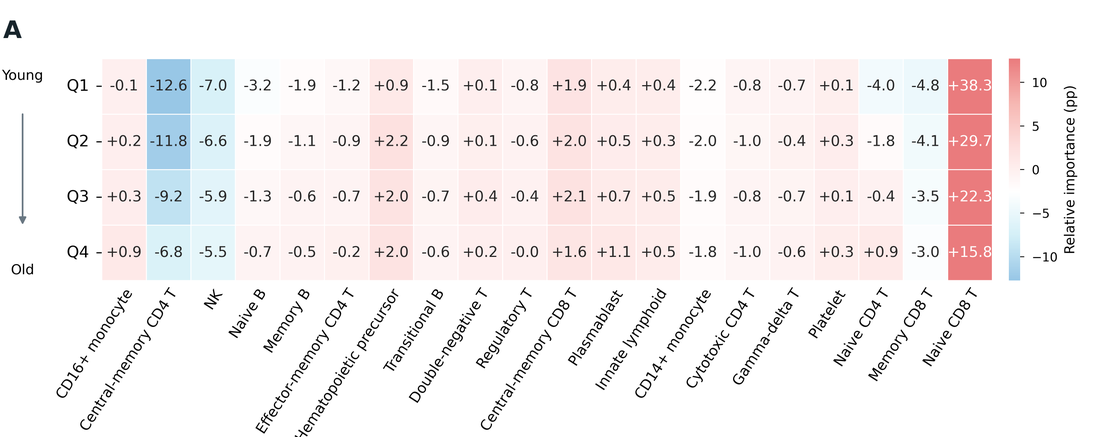

In [4]:
render_functional_panels(ANALYSIS_DIR, OUTPUT_DIR)
show_figure(OUTPUT_DIR / 'Figure8A.png', width=672)


## Technical covariates


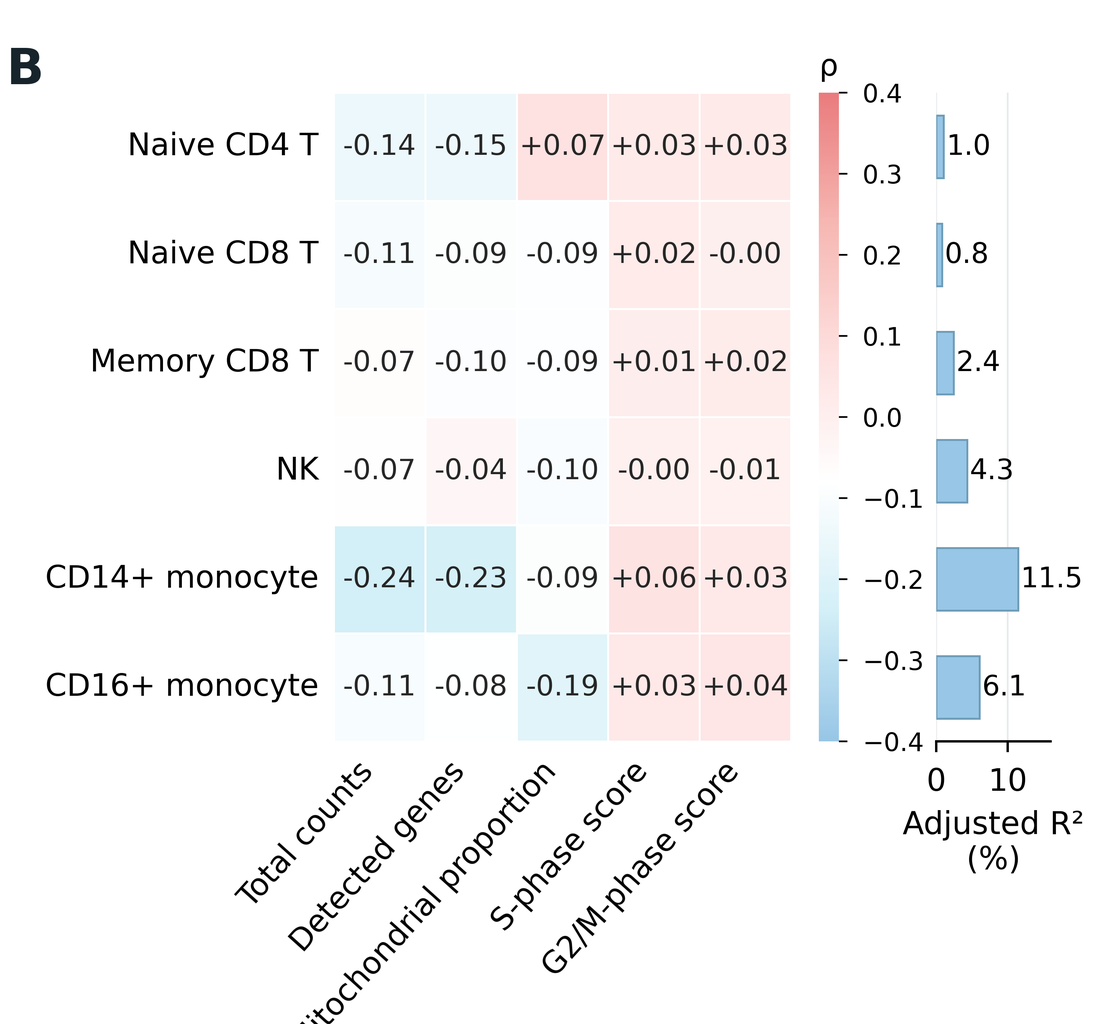

In [5]:
show_figure(OUTPUT_DIR / 'Figure8B.png', width=672)


## Hallmark associations


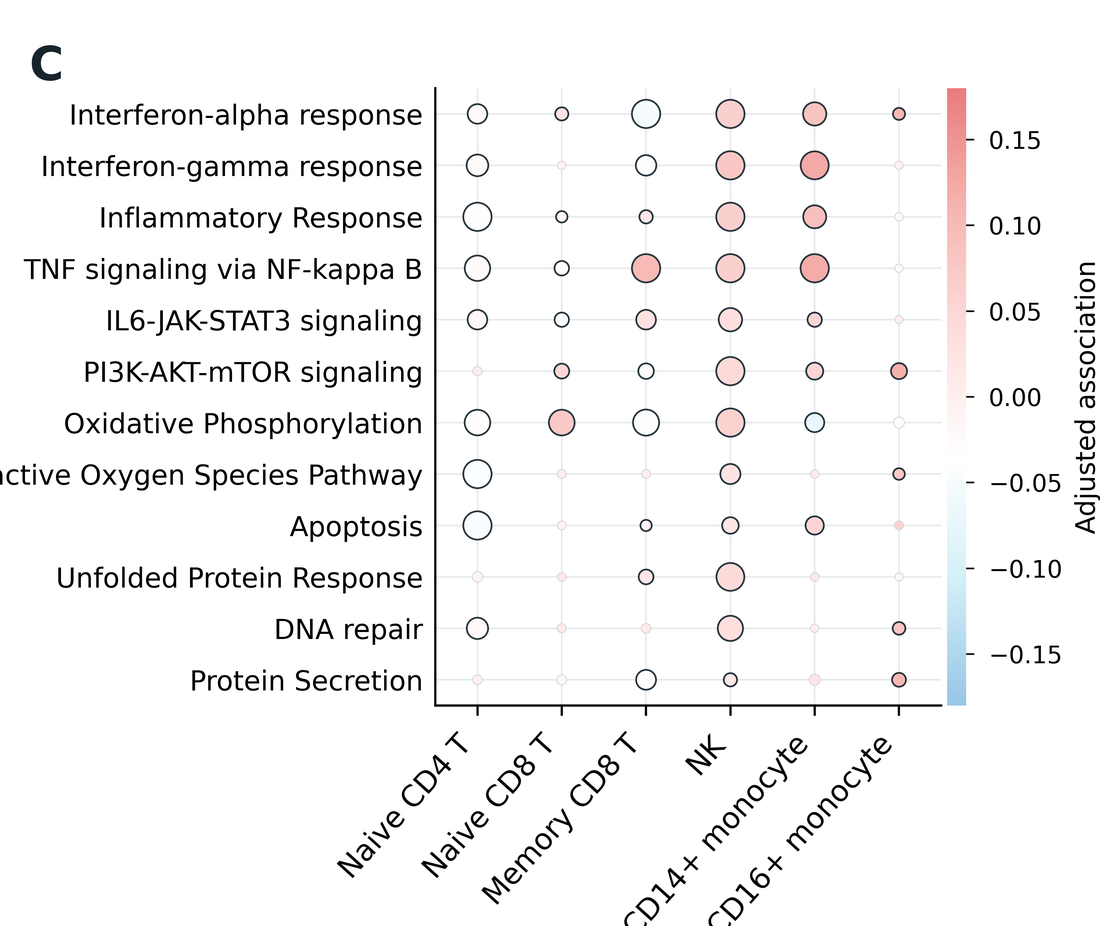

In [6]:
show_figure(OUTPUT_DIR / 'Figure8C.png', width=672)


## Activity contrasts


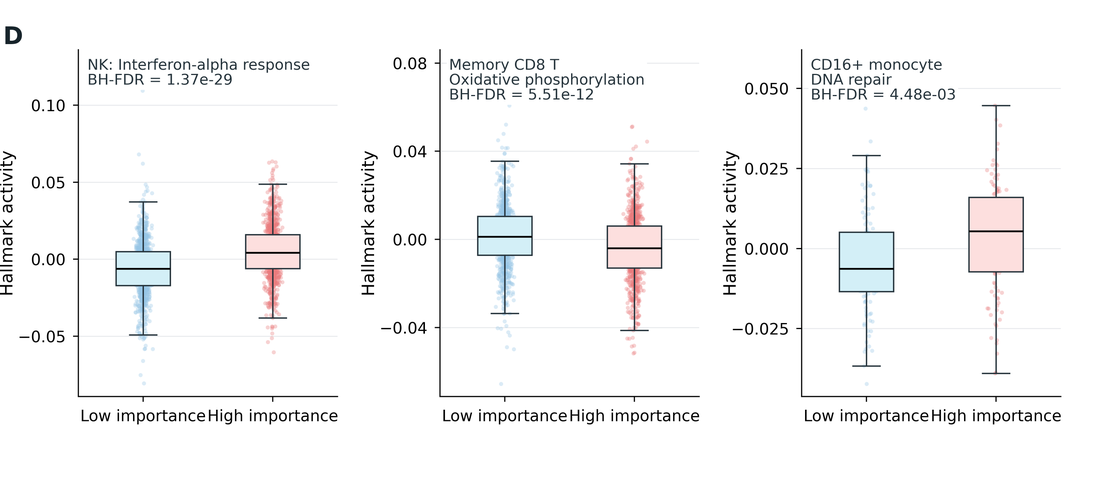

In [7]:
show_figure(OUTPUT_DIR / 'Figure8D.png', width=672)


## Contrast statistics


In [8]:
contrast_rows = []
for cell_type, hallmark, _ in FUNCTIONAL_CONTRASTS:
    row = hallmark_summary[hallmark_summary.cell_type.eq(cell_type) & hallmark_summary.hallmark.eq(hallmark)].iloc[0]
    contrast_rows.append({'Cell type': display_name(cell_type), 'Hallmark': hallmark,
                          'Individuals': int(row.n_donors), 'BH-FDR': f'{row.delta_fdr:.2e}'})
display(pd.DataFrame(contrast_rows))


,Cell type,Hallmark,Individuals,BH-FDR
0,NK,Interferon-alpha response,961,1.37e-29
1,Memory CD8 T,Oxidative Phosphorylation,910,5.51e-12
2,CD16+ monocyte,DNA repair,116,4.48e-03
